# SunVolt Energy: Solar Backup Customer Analysis
ITCDA4-34 Project, Questions 1 to 4

This notebook works through the SunVolt customer data to find out who buys solar backup systems and who doesn't.
Run the cells in order. The charts are saved in the `outputs/figures` folder.

## Loading and cleaning the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from pathlib import Path

fig_folder = Path("outputs/figures")
fig_folder.mkdir(parents=True, exist_ok=True)

# "Midnight solar" theme: dark navy background like a pitch deck, with gold for the best group,
# coral for the worst and muted slate for everything else
BG = "#0B1622"        # page background
CARD = "#14243A"      # panels and KPI cards
TEXT = "#F4F1EA"      # main text
MUTED = "#8DA2B8"     # labels and notes
GOLD = "#FFB627"      # best group / opportunity
CORAL = "#FF5A5F"     # worst group / problem
SLATE = "#3A5573"     # everything else

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TEXT, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": SLATE, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "font.family": "Segoe UI", "font.size": 10,
})
TITLE_FONT = "Bahnschrift"   # clean, slightly condensed font for headlines and big numbers

In [2]:
raw = pd.read_excel("SunVolt Solar Customer Data.xlsx")
print("Rows in file:", len(raw))
print("Duplicate rows:", raw.duplicated().sum())
print("Missing values:", raw.isna().sum().sum())

# some customers appear twice with exactly the same details, so we keep one copy of each
df = raw.drop_duplicates().reset_index(drop=True)

avg = df["Purchase Flag"].mean()
print("\nCustomers after cleaning:", len(df))
print("Customers who bought:", df["Purchase Flag"].sum())
print(f"Overall purchase rate: {avg:.1%}")

Rows in file: 1026
Duplicate rows: 26
Missing values: 0

Customers after cleaning: 1000
Customers who bought: 481
Overall purchase rate: 48.1%


### Helper functions
`purchase_rate()` works out the share of customers who bought in each group.
`plot_rate()` draws a bar chart of those rates with the overall average as a dashed line.
It also runs a chi-square test. The best (gold) and worst (coral) bars are only highlighted when the test is significant (p < 0.05). Otherwise all bars stay slate, because the difference could just be chance.

In [3]:
# keep these categories in their natural order instead of alphabetical
order = {
    "Age Group": ["Under 30", "30-39", "40-49", "50-59", "60+"],
    "Income Band": ["<30k", "30k-49k", "50k-69k", "70k-99k", "100k+"],
    "Distance from Nearest Installer": ["0-1 km", "1-2 km", "2-5 km", "5-10 km", "10+ km"],
    "Region": ["North America", "Europe", "Pacific"],
}

def purchase_rate(column):
    table = df.groupby(column)["Purchase Flag"].agg(customers="count", rate="mean")
    if column in order:
        table = table.reindex(order[column])
    return table

def chi_square_p(column):
    counts = pd.crosstab(df[column], df["Purchase Flag"])
    return chi2_contingency(counts)[1]

def plot_rate(ax, column, title):
    table = purchase_rate(column)
    rates = table["rate"]
    p = chi_square_p(column)

    colours = []
    for r in rates:
        if p < 0.05 and r == rates.max():
            colours.append(GOLD)
        elif p < 0.05 and r == rates.min():
            colours.append(CORAL)
        else:
            colours.append(SLATE)

    labels = [f"{name}\nn={n}" for name, n in zip(table.index, table["customers"])]
    x = range(len(rates))

    # a wider, see-through bar behind the gold and coral bars gives them a glow
    for i, c in enumerate(colours):
        if c != SLATE:
            ax.bar(i, rates.iloc[i], color=c, width=0.85, alpha=0.18)
    ax.bar(x, rates, color=colours, width=0.6)

    for i, r in enumerate(rates):
        ax.text(i, r + 0.025, f"{r:.0%}", ha="center", fontsize=12, fontfamily=TITLE_FONT,
                color=TEXT if colours[i] == SLATE else colours[i])

    ax.axhline(avg, color=TEXT, linestyle=":", linewidth=1, alpha=0.6, zorder=0)
    ax.text(len(rates) - 0.45, avg, f"avg\n{avg:.0%}", va="center", fontsize=8, color=MUTED)
    ax.set_xlim(-0.6, len(rates) - 0.05)   # leaves room on the right for the avg label

    ax.set_xticks(list(x), labels)
    ax.set_ylim(0, 0.8)
    ax.set_yticks([])
    ax.tick_params(axis="x", length=0, labelsize=8.5)
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    if p >= 0.05:
        p_text += "  ·  not significant"
    ax.set_title(title, loc="left", fontsize=13, fontfamily=TITLE_FONT, color=TEXT, pad=22)
    ax.text(0, 1.03, f"Purchase rate by {column.lower()}  ·  {p_text}", transform=ax.transAxes, fontsize=8.5, color=MUTED)

### Which customer details are linked to buying?
A chi-square test is run for each column. A p-value below 0.05 means the purchase rate really does differ between the groups.

In [4]:
columns = ["Age Group", "Income Band", "Gender", "Marital Status", "Household Dependents", "Homeowner Status",
           "Vehicles Owned", "Education Level", "Occupation", "Region", "Distance from Nearest Installer"]

results = []
for col in columns:
    p = chi_square_p(col)
    results.append({"Attribute": col, "p-value": round(p, 4), "Significant": p < 0.05})

pd.DataFrame(results).sort_values("p-value").reset_index(drop=True)

,Attribute,p-value,Significant
0,Age Group,0.0000,True
1,Household Dependents,0.0000,True
2,Vehicles Owned,0.0000,True
3,Education Level,0.0000,True
4,Distance from Nearest Installer,0.0000,True
5,Marital Status,0.0005,True
6,Region,0.0010,True
7,Occupation,0.0914,False
8,Income Band,0.3506,False
9,Gender,0.6769,False


Seven of the eleven details are linked to buying. Income band, gender, occupation and home ownership are not.

---
## Question 1: Exploratory and explanatory analysis

### I. Customer demographics

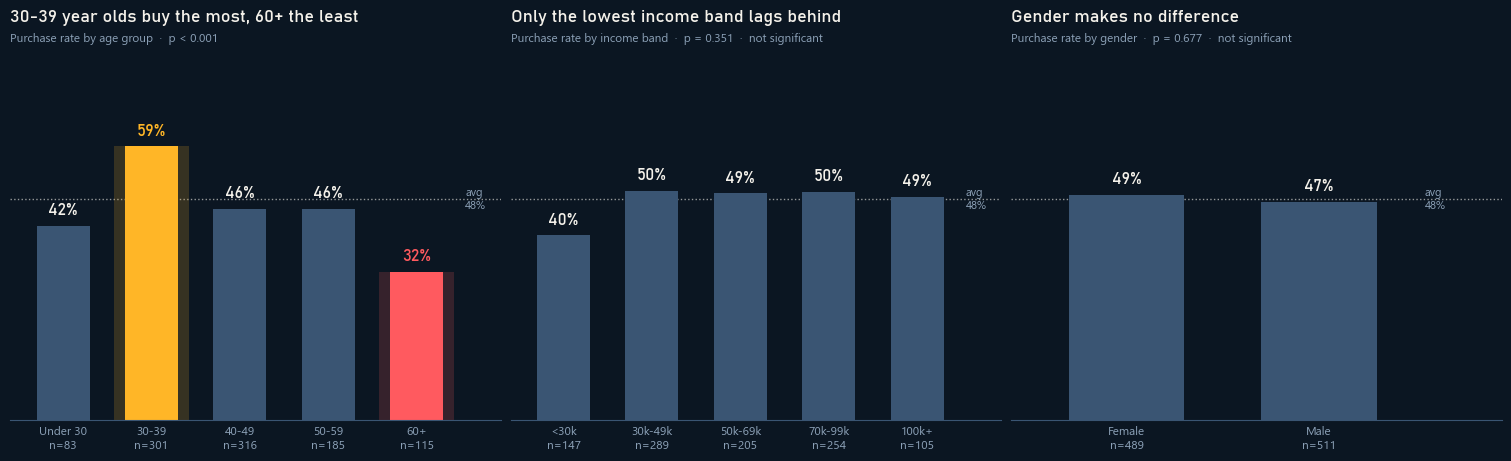

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
plot_rate(axes[0], "Age Group", "30-39 year olds buy the most, 60+ the least")
plot_rate(axes[1], "Income Band", "Only the lowest income band lags behind")
plot_rate(axes[2], "Gender", "Gender makes no difference")
fig.savefig(fig_folder / "q1_demographics.png", dpi=200, bbox_inches="tight")
plt.show()

**What the charts show**
- Age matters most. Customers aged 30 to 39 buy at 59.5% and make up 37% of all buyers. Customers aged 60 and over buy at only 32.2%.
- Income on its own is weak. Every band from 30k upwards buys at about 49% to 50%. Only customers earning under 30k fall behind (40.1%), which points to cost as a barrier.
- Gender has no effect (women 48.9%, men 47.4%, p = 0.68), so there is no need for separate marketing by gender.

**Groups that mostly don't buy, and how to reach them**

| Group | Share not buying | Likely barrier | How to engage them |
|---|---|---|---|
| 5 dependents | 78% | Cash flow | Monthly payment plans for families |
| 10+ km from an installer | 70% | Access and service | Mobile installers and remote monitoring |
| Aged 60+ | 68% | Long payback, unsure about the technology | Package with full maintenance included |
| 2+ vehicles | 63% | Money already going to cars | EV charger and solar bundle |
| Income under 30k | 60% | Affordability | Cheaper starter kit or rent-to-own |

### II. Geographical insights

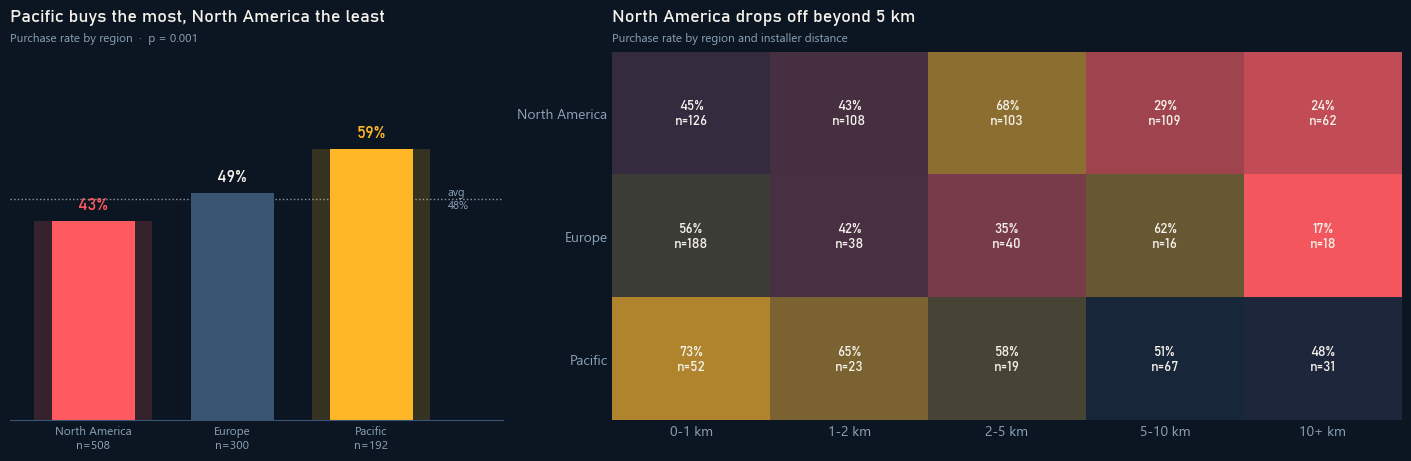

,customers,rate,non_buyers
Region,,,
North America,508,0.433071,288
Europe,300,0.493333,152
Pacific,192,0.588542,79


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), width_ratios=[1, 1.6], layout="constrained")
plot_rate(axes[0], "Region", "Pacific buys the most, North America the least")

# purchase rate for every region and distance combination
regions = order["Region"]
distances = order["Distance from Nearest Installer"]
heat = df.pivot_table(index="Region", columns="Distance from Nearest Installer", values="Purchase Flag", aggfunc="mean")
heat = heat.loc[regions, distances]
counts = pd.crosstab(df["Region"], df["Distance from Nearest Installer"]).loc[regions, distances]

# coral = below average, dark blue = around average, gold = above average
red_to_amber = LinearSegmentedColormap.from_list("coral_to_gold", [CORAL, CARD, GOLD])
axes[1].imshow(heat, cmap=red_to_amber, vmin=0.15, vmax=0.85, aspect="auto")
axes[1].spines[:].set_visible(False)
axes[1].tick_params(length=0)
axes[1].set_xticks(range(len(distances)), distances)
axes[1].set_yticks(range(len(regions)), regions)
for i in range(len(regions)):
    for j in range(len(distances)):
        axes[1].text(j, i, f"{heat.iloc[i, j]:.0%}\nn={counts.iloc[i, j]}", ha="center", va="center", fontsize=10, fontfamily=TITLE_FONT, color=TEXT)
axes[1].set_title("North America drops off beyond 5 km", loc="left", fontsize=13, fontfamily=TITLE_FONT, pad=22)
axes[1].text(0, 1.03, "Purchase rate by region and installer distance", transform=axes[1].transAxes, fontsize=8.5, color=MUTED)

fig.savefig(fig_folder / "q1_region.png", dpi=200, bbox_inches="tight")
plt.show()

region_table = purchase_rate("Region")
region_table["non_buyers"] = (region_table["customers"] * (1 - region_table["rate"])).round().astype(int)
region_table

- The Pacific has the highest purchase rate (58.9%), then Europe (49.3%), with North America lowest (43.3%), p = 0.001.
- North America has 51% of all customers and 288 people who haven't bought. That is the biggest group we could still win. If North America bought at the Pacific rate, that would be about 79 more systems.
- Only 25% of North American customers live within 1 km of an installer, compared with 63% in Europe. Beyond 5 km, North American purchase rates fall to 24% to 29%.

**Strategies by region**
- North America: get installers closer to suburban customers using mobile or partner installers, and offer finance.
- Europe has the lowest incomes, so focus on finance and pricing.
- Pacific: build on what is working with more stock, marketing and referral rewards.

### III. Purchase influences

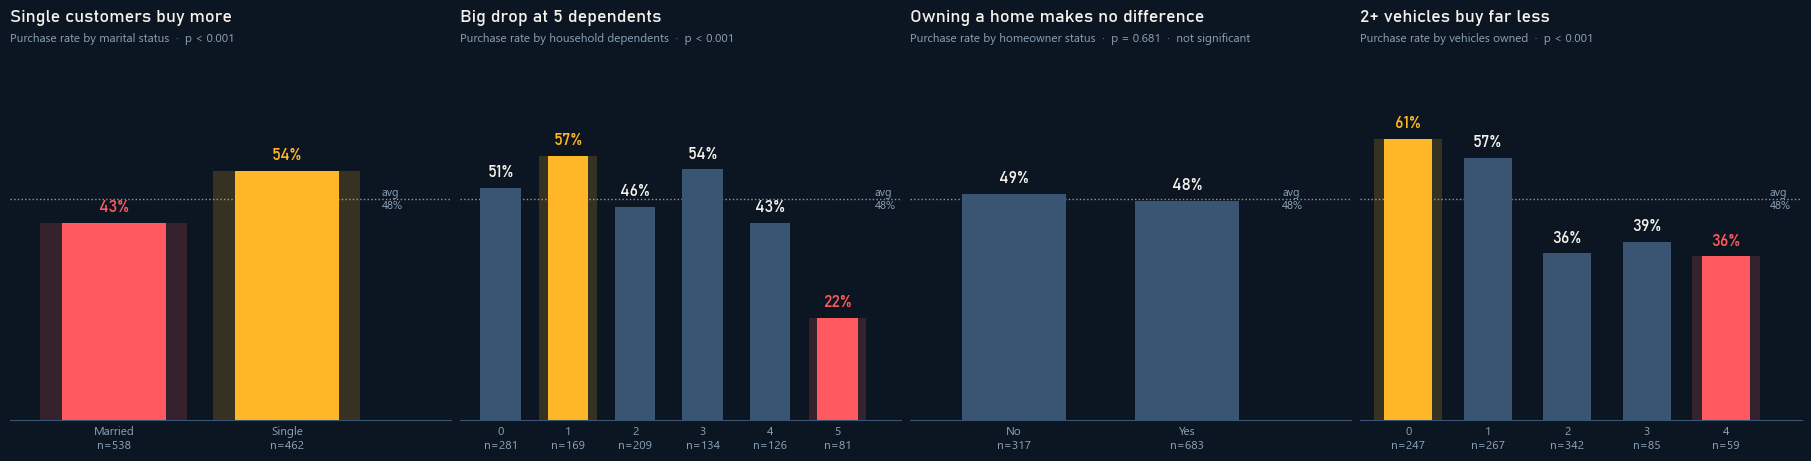

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), layout="constrained")
plot_rate(axes[0], "Marital Status", "Single customers buy more")
plot_rate(axes[1], "Household Dependents", "Big drop at 5 dependents")
plot_rate(axes[2], "Homeowner Status", "Owning a home makes no difference")
plot_rate(axes[3], "Vehicles Owned", "2+ vehicles buy far less")
fig.savefig(fig_folder / "q1_influences.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# look at pairs of attributes to find large groups that buy less than average
pairs = [("Marital Status", "Region"), ("Marital Status", "Vehicles Owned"),
         ("Region", "Distance from Nearest Installer"), ("Marital Status", "Age Group"),
         ("Vehicles Owned", "Household Dependents"), ("Age Group", "Region")]

rows = []
for a, b in pairs:
    groups = df.groupby([a, b])["Purchase Flag"].agg(customers="count", rate="mean").reset_index()
    for _, g in groups.iterrows():
        if g["customers"] >= 30:   # ignore very small groups
            rows.append({"Segment": f"{a} = {g[a]}, {b} = {g[b]}",
                         "customers": int(g["customers"]),
                         "rate": round(g["rate"], 3),
                         # extra buyers if this group bought at the average rate
                         "extra_buyers": round((avg - g["rate"]) * g["customers"])})

segments = pd.DataFrame(rows).sort_values("extra_buyers", ascending=False)
segments.head(6)

,Segment,customers,rate,extra_buyers
1,"Marital Status = Married, Region = North America",297,0.360,36
8,"Marital Status = Married, Vehicles Owned = 2",190,0.300,34
29,"Marital Status = Married, Age Group = 60+",76,0.224,20
22,"Region = North America, Distance from Nearest ...",109,0.294,20
20,"Region = North America, Distance from Nearest ...",62,0.242,15
27,"Marital Status = Married, Age Group = 40-49",191,0.403,15


- Marital status: single customers buy at 54.1%, married customers at 42.9% (p < 0.001).
- Dependents: households with 0 to 3 dependents buy at 46% to 57%. That falls to 42.9% with 4 dependents and 22.2% with 5, mostly large married families.
- Home ownership makes no difference (owners 47.6%, renters 49.2%, p = 0.68). Renters are 32% of customers and could be offered a portable system that doesn't need installing.
- Vehicles have the strongest effect: customers with 0 or 1 vehicle buy at 57% to 61%, but those with 2 or more buy at only 36% to 39%.

**Untapped segments:** married North Americans (297 customers, 36%), married customers with 2 vehicles (30%), North Americans 5 to 10 km from an installer (29%) and married customers aged 60+ (22%). Family finance, EV bundles and mobile installers would suit these groups.

### IV. Distance from nearest installer

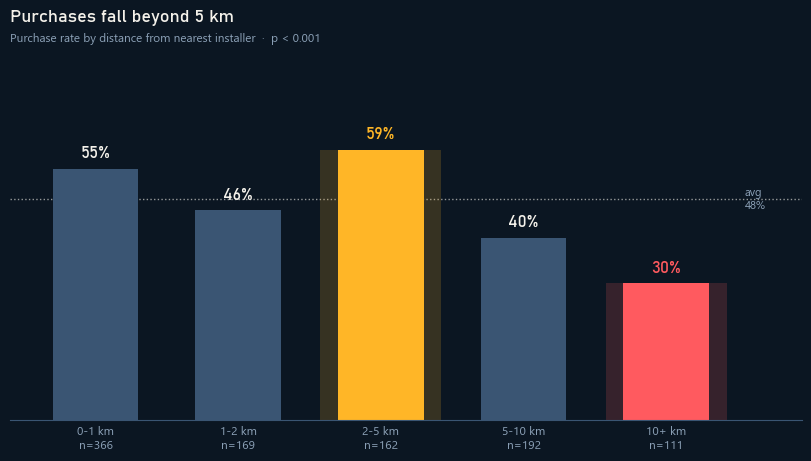

Within 5 km: 53.4% of 697 customers
Beyond 5 km: 36.0% of 303 customers


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
plot_rate(ax, "Distance from Nearest Installer", "Purchases fall beyond 5 km")
fig.savefig(fig_folder / "q1_distance.png", dpi=200, bbox_inches="tight")
plt.show()

far = df["Installer Distance Order"] >= 4   # 5-10 km and 10+ km
near_rate = df.loc[~far, "Purchase Flag"].mean()
far_rate = df.loc[far, "Purchase Flag"].mean()
print(f"Within 5 km: {near_rate:.1%} of {(~far).sum()} customers")
print(f"Beyond 5 km: {far_rate:.1%} of {far.sum()} customers")

- Customers closer to an installer buy more: 53.4% within 5 km against 36.0% beyond 5 km, and only 29.7% at 10 km or more. About 30% of customers live more than 5 km away.
- Recommendations:
  - 0 to 5 km: quick installs and referral rewards.
  - 5 to 10 km: free site visits and partner installers.
  - 10 km and more: mobile installation vans and remote monitoring. Use this data to decide where new branches go, starting with North America.

---
## Question 2: Executive dashboard for the CEO and investors
The dashboard puts the main message at the top, then the key numbers, then the charts that explain the problem, and finally the recommended actions.
It uses the same dark theme as the slides. Gold marks the best group, coral the worst and slate everything else.

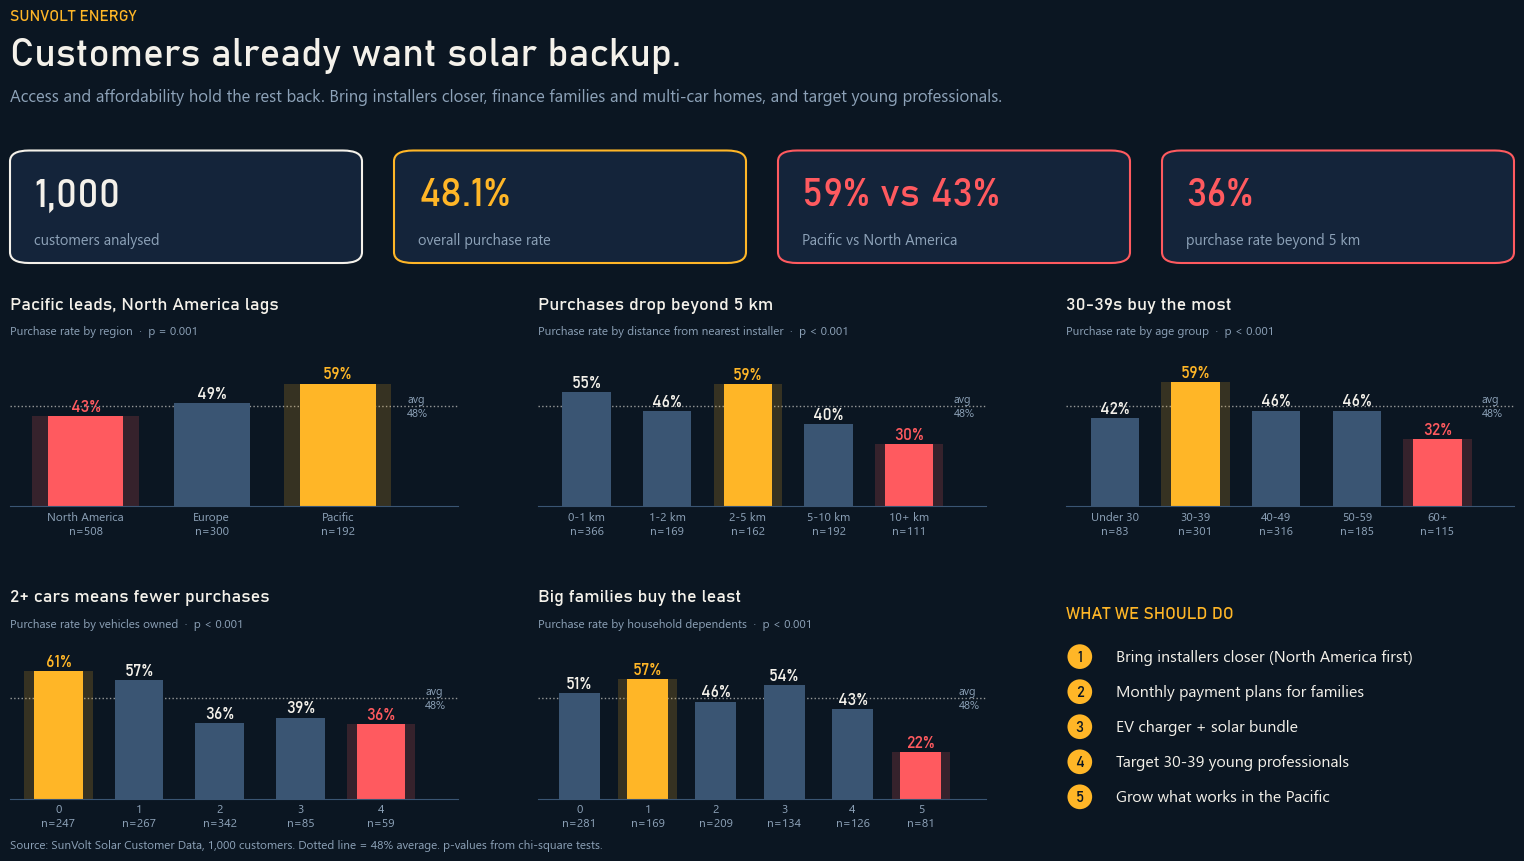

In [10]:
from matplotlib.patches import FancyBboxPatch

fig = plt.figure(figsize=(16, 9))

# header
fig.text(0.03, 0.935, "SUNVOLT ENERGY", fontsize=11, color=GOLD, fontfamily=TITLE_FONT)
fig.text(0.03, 0.885, "Customers already want solar backup.", fontsize=28, fontfamily=TITLE_FONT, color=TEXT)
fig.text(0.03, 0.845, "Access and affordability hold the rest back. Bring installers closer, finance families "
         "and multi-car homes, and target young professionals.", fontsize=12, color=MUTED)

# KPI cards
kpis = [("1,000", "customers analysed", TEXT),
        (f"{avg:.1%}", "overall purchase rate", GOLD),
        ("59% vs 43%", "Pacific vs North America", CORAL),
        (f"{far_rate:.0%}", "purchase rate beyond 5 km", CORAL)]
for i, (value, label, colour) in enumerate(kpis):
    x = 0.03 + i * 0.24
    card = FancyBboxPatch((x, 0.665), 0.22, 0.125, boxstyle="round,pad=0,rounding_size=0.012",
                          transform=fig.transFigure, facecolor=CARD, edgecolor=colour, linewidth=1.5)
    fig.add_artist(card)
    fig.text(x + 0.015, 0.74, value, fontsize=28, fontfamily=TITLE_FONT, color=colour, va="center")
    fig.text(x + 0.015, 0.69, label, fontsize=10.5, color=MUTED, va="center")

grid = fig.add_gridspec(2, 3, left=0.03, right=0.97, top=0.58, bottom=0.07, hspace=0.75, wspace=0.18)
charts = [("Region", "Pacific leads, North America lags"),
          ("Distance from Nearest Installer", "Purchases drop beyond 5 km"),
          ("Age Group", "30-39s buy the most"),
          ("Vehicles Owned", "2+ cars means fewer purchases"),
          ("Household Dependents", "Big families buy the least")]
for k, (col, title) in enumerate(charts):
    plot_rate(fig.add_subplot(grid[k // 3, k % 3]), col, title)

# recommended actions
ax = fig.add_subplot(grid[1, 2])
ax.axis("off")
ax.text(0, 1.08, "WHAT WE SHOULD DO", fontsize=12, color=GOLD, fontfamily=TITLE_FONT)
actions = ["Bring installers closer (North America first)", "Monthly payment plans for families",
           "EV charger + solar bundle", "Target 30-39 young professionals", "Grow what works in the Pacific"]
for i, action in enumerate(actions):
    y = 0.85 - i * 0.21
    ax.text(0.03, y, str(i + 1), fontsize=11, color=BG, ha="center", va="center", fontfamily=TITLE_FONT,
            bbox=dict(boxstyle="circle,pad=0.35", facecolor=GOLD, edgecolor="none"))
    ax.text(0.11, y, action, fontsize=11.5, color=TEXT, va="center")

fig.text(0.03, 0.015, "Source: SunVolt Solar Customer Data, 1,000 customers. Dotted line = 48% average. "
         "p-values from chi-square tests.", fontsize=8.5, color=MUTED)
fig.savefig(fig_folder / "q2_dashboard.png", dpi=200)
plt.show()

---
## Question 3: Big Idea, 3-minute story and storyboard

**Big Idea:** *SunVolt's customers already want solar backup. By bringing installers closer, financing families and multi-car households, and targeting young professionals, we can turn 48% adoption into market leadership, starting in North America.*

**3-minute story**

> Almost one in two of our customers already owns a SunVolt backup system, so the demand is there. The real question is why the other half haven't bought. We looked at 1,000 customers across North America, Europe and the Pacific. 481 of them, or 48%, own a system. In the Pacific 59% buy, but in North America, where half our customers live, only 43% do. That leaves 288 North American customers who haven't bought yet, our biggest untapped group.
>
> The main reason is not who these customers are but how far they live from us. Within 5 km of an installer, 53% buy. Beyond 5 km only 36% do, and past 10 km just 30%. Three in ten customers live more than 5 km away. This is an access problem, not a demand problem.
>
> The second barrier is the household budget. Customers in their thirties buy the most, almost 60%. Homes with two or more cars buy at 37% and families with five dependents at 22%. Their money is already going to cars, fuel and children. Gender makes no difference at all, so marketing aimed at men or women separately is wasted.
>
> What is at stake? If customers far from an installer bought like those nearby, we would sell about 53 more systems. If North America bought like the Pacific, we would sell about 79 more. All of these customers are already in our database, and any we don't convert could be won by a competitor.
>
> We recommend three moves. First, bring installers closer with mobile teams and partner installers, starting in North America. Second, make it affordable with monthly payment plans for families and an EV and solar bundle. Third, target better by focusing on young professionals and growing what already works in the Pacific. Our customers already want solar, so let's remove what is stopping them. We ask for approval to pilot these moves in North America next quarter.

**Storyboard (setting, conflict, resolution)**

| Slide | Part | Headline | Visual |
|---|---|---|---|
| 1 | Setting | Our customers already want solar backup | Title and Big Idea |
| 2 | Setting | Almost 1 in 2 have already bought (48%) | Key numbers |
| 3 | Conflict | North America buys the least (43%) | Region chart |
| 4 | Conflict | Beyond 5 km, purchases drop by a third | Distance chart |
| 5 | Conflict | 30-39s buy most; multi-car homes and big families least | Age, vehicle and dependents charts |
| 6 | Resolution | One dashboard to track progress | Dashboard |
| 7 | Resolution | Three moves: closer, affordable, better targeting | Three columns of actions |
| 8 | Resolution | Approve a North America pilot | The request and the KPIs to track |

---
## Question 4: Presentation
The slides are in `outputs/SunVolt_Presentation.pptx` (8 slides with speaker notes, following the storyboard above).
The video was recorded from these slides in PowerPoint (Slide Show > Record, then File > Export > Create a Video).